In [18]:
import random
import matplotlib.pyplot as plt

random.seed(109)

In [19]:
class Mancala:
    # ------------------------ Helpers -------------------------- 

    # get the other player
    def _other(self, player):
        return 2 if player == 1 else 1

    # get the pit indices of the player vs the enemy 
    def _pit_indices(self, player):
        start, end = self.p1_pits_index if player == 1 else self.p2_pits_index
        return range(start, end + 1)

    # get the mancala index of the player vs the enemy 
    def _mancala_index(self, player):
        return self.p1_mancala_index if player == 1 else self.p2_mancala_index

    # Get the board index of the pit directly across from it 
    def _opposite_index(self, index):
        if index in self._pit_indices(1):
            offset = index - self.p1_pits_index[0]
            return self.p2_pits_index[1] - offset
        offset = index - self.p2_pits_index[0]
        return self.p1_pits_index[1] - offset

    # Get the winner 
    def get_winner(self):
        if not self.winning_eval():
            return None
        p1 = self.board[self.p1_mancala_index]
        p2 = self.board[self.p2_mancala_index]
        if p1 == p2:
            return 0
            
        return 1 if p1 > p2 else 2
    # ------------------------ Code ----------------------------------------- 
    def __init__(self, pits_per_player=6, stones_per_pit = 4):
        """
        The constructor for the Mancala class defines several instance variables:

        pits_per_player: This variable stores the number of pits each player has.
        stones_per_pit: It represents the number of stones each pit contains at the start of any game.
        board: This data structure is responsible for managing the Mancala board.
        current_player: This variable takes the value 1 or 2, as it's a two-player game, indicating which player's turn it is.
        moves: This is a list used to store the moves made by each player. It's structured in the format (current_player, chosen_pit).
        p1_pits_index: A list containing two elements representing the start and end indices of player 1's pits in the board data structure.
        p2_pits_index: Similar to p1_pits_index, it contains the start and end indices for player 2's pits on the board.
        p1_mancala_index and p2_mancala_index: These variables hold the indices of the Mancala pits on the board for players 1 and 2, respectively.
        """
        self.pits_per_player = pits_per_player
        self.board = [stones_per_pit] * ((pits_per_player+1) * 2)  # Initialize each pit with stones_per_pit number of stones 
        self.players = 2
        self.current_player = 1
        self.moves = []
        # Continuations 
        self.continuations = 0
        self.p1_pits_index = [0, self.pits_per_player-1]
        self.p1_mancala_index = self.pits_per_player
        self.p2_pits_index = [self.pits_per_player+1, len(self.board)-1-1]
        self.p2_mancala_index = len(self.board)-1
        
        # Zeroing the Mancala for both players
        self.board[self.p1_mancala_index] = 0
        self.board[self.p2_mancala_index] = 0

    def display_board(self):
        """
        Displays the board in a user-friendly format
        """
        player_1_pits = self.board[self.p1_pits_index[0]: self.p1_pits_index[1]+1]
        player_1_mancala = self.board[self.p1_mancala_index]
        player_2_pits = self.board[self.p2_pits_index[0]: self.p2_pits_index[1]+1]
        player_2_mancala = self.board[self.p2_mancala_index]

        print('P1               P2')
        print('     ____{}____     '.format(player_2_mancala))
        for i in range(self.pits_per_player):
            if i == self.pits_per_player - 1:
                print('{} -> |_{}_|_{}_| <- {}'.format(i+1, player_1_pits[i], 
                        player_2_pits[-(i+1)], self.pits_per_player - i))
            else:    
                print('{} -> | {} | {} | <- {}'.format(i+1, player_1_pits[i], 
                        player_2_pits[-(i+1)], self.pits_per_player - i))
            
        print('         {}         '.format(player_1_mancala))
        turn = 'P1' if self.current_player == 1 else 'P2'
        print('Turn: ' + turn)
        print()  # blank line between boards
        
    def valid_move(self, pit):
        """
        Function to check if the pit chosen by the current_player is a valid move.
        """

         # Must be a whole number
        if not isinstance(pit, int):
            return False

        # Check for real pit number (1 to pits_per_player)
        if pit < 1 or pit > self.pits_per_player:
            return False

        # Must have stones in it
        index = self._pit_indices(self.current_player)[pit - 1]
        return self.board[index] > 0
        
    def random_move_generator(self):
        """
        Function to generate random valid moves with non-empty pits for the random player
        """
        options = []
        # pit numbers 1..6
        for pit in range(1, self.pits_per_player + 1):  
            # check if non empty
            if self.valid_move(pit):                       
                options.append(pit)
    
        # no legal moves 
        if len(options) == 0:       
            return None
        return random.choice(options)
    
    def play(self, pit):
        """
        This function simulates a single move made by the current player using their selected pit (1-indexed).
        Do these checks in this order:
        1. If the game is already over (winning_eval() returns True), print "GAME OVER" and take no further action.
        2. Otherwise, if the chosen pit is not a valid move for the current player, print "INVALID MOVE" and take no action.
           The current player stays the same.
        3. Otherwise, distribute the stones according to the Mancala rules, including captures, and add
           (current_player, pit) to self.moves.

        Finally, apply the continuation rule: if the last stone landed in the current player's own mancala,
        the same player moves again; otherwise switch the current player so the other player takes their turn.
        If the move ends the game, there is no extra turn.

        Returns the board (self.board).
        """

        # check if game if over 
        if self.winning_eval():
            print("GAME OVER")
            return self.board
        # Check for valid move 
        if not self.valid_move(pit):
            print("INVALID MOVE")
            return self.board
            
        # Else distribute acoording to manacla moves 

        # get whose playing 
        player = self.current_player
        player_mancala = self._mancala_index(player)
        enemy_mancala = self._mancala_index(self._other(player))
        self.moves.append((player, pit))

        # 1) get all the stones from the chosen pit 
        index = self._pit_indices(player)[pit - 1]
        stones = self.board[index]
        self.board[index] = 0

        # 2) drop 1 stone per pit cc skipping opponents mancala 
        while stones > 0:
            index = (index + 1) % len(self.board)
            if index == enemy_mancala:
                continue
            self.board[index] += 1
            stones -= 1

        # 3) Capture (if u land in empty pit cature the stone and enemy pit stones) 
        if index in self._pit_indices(player) and self.board[index] == 1:
            opposite = self._opposite_index(index)
            self.board[player_mancala] += self.board[index] + self.board[opposite]
            self.board[index] = 0
            self.board[opposite] = 0

        # 4) check if this won the game 
        game_over = self.winning_eval()
        if game_over:
            winner = self.get_winner()
            if winner == 0:
                print("It's a tie!")
            else:
                print(f"Player {winner} wins!")

        # 5) continuation rule 
        if index == player_mancala and not game_over:
            self.continuations += 1 
            return self.board 
            
        self.current_player = self._other(player)

        # write your code here
        return self.board
    
    def winning_eval(self):
        """
        Function to verify if the game board has reached the winning state.
        Hint: If either of the players' pits are all empty, then it is considered a winning state.
        When the game is over, move any stones left on a player's side into that player's mancala.

        Returns True if the game is over and False otherwise (always a bool, never None or the winner).
        To report the winner, compare the two mancalas after winning_eval() returns True.
        """
        p1_empty = all(self.board[i] == 0 for i in self._pit_indices(1))
        p2_empty = all(self.board[i] == 0 for i in self._pit_indices(2))
        if not (p1_empty or p2_empty):
            return False

        for player in (1, 2):
            mancala = self._mancala_index(player)
            for i in self._pit_indices(player):
                self.board[mancala] += self.board[i]
                self.board[i] = 0
        return True     


In [20]:
# ------------------------------- Driver Code ------------------------------
# Create a 6-pit (12 pits + 2 mancalas), 4-stone game,
# Both players will be playing random moves 


# ---------------------------- Helper Functions ----------------------------
def prct(n):
    # for calculating percent when nu Gmaes isnt always 100
    return 100 * n / NUM_GAMES

# Constants 
NUM_GAMES = 100
wins = {1: 0, 2: 0}
ties = 0 
turns = 0
continuations = 0

# -------- Display the board setup used for the 100 games ------------------
game = Mancala(pits_per_player=6, stones_per_pit=4)
game.display_board()


# --------------------------------------------------------------------------

# Driver loop
for _ in range(NUM_GAMES):
    # 1) Set the game board 
    game = Mancala(pits_per_player=6, stones_per_pit=4)

    # 2) Play the game until theres a winner 
    while not game.winning_eval():
        game.play(game.random_move_generator())
        
    # 3) Determine the winner and update scores
    winner = game.get_winner()
    if winner == 0:
        ties += 1
    else:
        wins[winner] += 1
        
    # 4) update totals 
    turns += len(game.moves)
    continuations += game.continuations

print(f"Random vs. Random, {NUM_GAMES} games\n")
for p in (1, 2):
    other = 2 if p == 1 else 1
    print(f"Player {p}: won {wins[p]} ({prct(wins[p])}%), "
          f"lost {wins[other]} ({prct(wins[other])}%), "
        f"tied {ties} ({prct(ties)}%)")

print()
print(f"nAverage moves per game: {turns / NUM_GAMES}")
print(f"Average continuations per game: {continuations / NUM_GAMES}")


P1               P2
     ____0____     
1 -> | 4 | 4 | <- 6
2 -> | 4 | 4 | <- 5
3 -> | 4 | 4 | <- 4
4 -> | 4 | 4 | <- 3
5 -> | 4 | 4 | <- 2
6 -> |_4_|_4_| <- 1
         0         
Turn: P1

Player 1 wins!
It's a tie!
Player 2 wins!
Player 1 wins!
Player 2 wins!
Player 2 wins!
Player 1 wins!
Player 2 wins!
Player 1 wins!
Player 1 wins!
Player 2 wins!
Player 2 wins!
Player 1 wins!
Player 2 wins!
Player 1 wins!
Player 1 wins!
Player 1 wins!
Player 1 wins!
Player 1 wins!
Player 1 wins!
Player 2 wins!
It's a tie!
Player 2 wins!
Player 2 wins!
Player 2 wins!
Player 2 wins!
Player 2 wins!
Player 1 wins!
Player 2 wins!
Player 2 wins!
Player 2 wins!
Player 2 wins!
Player 2 wins!
Player 2 wins!
Player 2 wins!
Player 2 wins!
Player 2 wins!
Player 1 wins!
Player 2 wins!
Player 1 wins!
Player 2 wins!
Player 1 wins!
Player 2 wins!
Player 1 wins!
Player 1 wins!
Player 2 wins!
Player 2 wins!
Player 1 wins!
Player 1 wins!
Player 1 wins!
Player 1 wins!
Player 1 wins!
Player 2 wins!
Player 1 wins!
Player

In [21]:
### AI
# ------------------------------- Minimax AI -------------------------------
import copy
import io
import contextlib

def clone(game):
    """Make an independent copy of the game so the AI can try moves
    without changing the real board."""
    new_game = copy.copy(game)
    new_game.board = game.board[:]
    new_game.moves = []
    return new_game

def utility(game, ai_player):
    """Utility = stones in the AI's mancala minus stones in the opponent's mancala."""
    opponent = 2 if ai_player == 1 else 1
    return game.board[game._mancala_index(ai_player)] - game.board[game._mancala_index(opponent)]

def legal_moves(game):
    return [pit for pit in range(1, game.pits_per_player + 1) if game.valid_move(pit)]

def minimax(game, depth, ai_player):
    """Returns the minimax value of this board, looking `depth` plies ahead.
    A ply is one move by one player. If a move earns an extra turn, the same
    player moves again on the next ply (MAX stays MAX, MIN stays MIN)."""
    if depth == 0 or game.winning_eval():
        return utility(game, ai_player)

    values = []
    for pit in legal_moves(game):
        child = clone(game)
        child.play(pit)
        values.append(minimax(child, depth - 1, ai_player))

    # MAX when it is the AI's turn, MIN when it is the opponent's turn
    if game.current_player == ai_player:
        return max(values)
    return min(values)

def minimax_move(game, depth):
    """Pick the pit with the best minimax value for the current player."""
    ai_player = game.current_player
    best_pit, best_value = None, float('-inf')
    for pit in legal_moves(game):
        child = clone(game)
        child.play(pit)
        value = minimax(child, depth - 1, ai_player)
        if value > best_value:
            best_pit, best_value = pit, value
    return best_pit


In [22]:
# ----------------------------- Alpha-Beta AI ------------------------------
import time

def ordered_moves(game):
    """Return (pit, child) pairs, best-looking first: extra turns first,
    then moves that put the most stones in the mover's mancala."""
    me = game.current_player
    my_mancala = game._mancala_index(me)
    kids = []
    
    for pit in legal_moves(game):
        child = clone(game)
        child.play(pit)
        extra_turn = child.current_player == me
        kids.append((not extra_turn, -child.board[my_mancala], pit, child))
        
    kids.sort(key=lambda k: (k[0], k[1]))
    return [(pit, child) for _, _, pit, child in kids]

def alphabeta(game, depth, alpha, beta, ai_player):
    """Minimax with alpha-beta pruning. Gives the same value as minimax(),
    but stops exploring a branch once it can't change the final choice.
    alpha = best value MAX is guaranteed so far, beta = best value MIN is guaranteed so far."""
    if depth == 0 or game.winning_eval():
        return utility(game, ai_player)

    # MAX node
    if game.current_player == ai_player:          
        value = float('-inf')
        for pit, child in ordered_moves(game):
            value = max(value, alphabeta(child, depth - 1, alpha, beta, ai_player))
            alpha = max(alpha, value)
            if alpha >= beta: # MIN should never allow this branch
                break
        return value
    # MIN node
    else:                                        
        value = float('inf')
        for pit, child in ordered_moves(game):
            value = min(value, alphabeta(child, depth - 1, alpha, beta, ai_player))
            beta = min(beta, value)
            if alpha >= beta: # MAX should never allow this branch
                break
        return value

def alphabeta_move(game, depth):
    """Pick the pit with the best alpha-beta value for the current player."""
    ai_player = game.current_player
    best_pit, best_value = None, float('-inf')
    alpha, beta = float('-inf'), float('inf')
    
    for pit, child in ordered_moves(game):
        value = alphabeta(child, depth - 1, alpha, beta, ai_player)
        if value > best_value:
            best_pit, best_value = pit, value
        alpha = max(alpha, best_value)
        
    return best_pit

def minimax_player(game, state, d):
    """Pit minimax chooses for the player to move in `state` (a Mancala object)."""
    return minimax_move(state, d + 1)

def alpha_beta_player(game, state, d):
    """Same as minimax_player, using Alpha-Beta pruning."""
    return alphabeta_move(state, d + 1)

In [ ]:

# ------------------------------- Driver Code ------------------------------
# AI is Player 1, Random is Player 2

def play_ai_vs_random_timed(choose_move, depth, label, num_games=100, seed=109):
    random.seed(seed)
    AI, RANDOM = 1, 2
    wins = {AI: 0, RANDOM: 0}
    ties = 0
    moves_in_won_games = {AI: [], RANDOM: []}
    winner_moves = {AI: [], RANDOM: []}
    game_times = []

    for _ in range(num_games):
        game = Mancala(pits_per_player=6, stones_per_pit=4)
        start = time.perf_counter()
        with contextlib.redirect_stdout(io.StringIO()):
            while not game.winning_eval():
                if game.current_player == AI:
                    game.play(choose_move(game, game, depth))
                else:
                    game.play(game.random_move_generator())
        game_times.append(time.perf_counter() - start)

        winner = game.get_winner()
        if winner == 0:
            ties += 1
        else:
            wins[winner] += 1
            moves_in_won_games[winner].append(len(game.moves))
            winner_moves[winner].append(sum(1 for p, _ in game.moves if p == winner))

    def avg(xs):
        return sum(xs) / len(xs) if xs else float('nan')

    print(label + " AI (" + str(depth) + " plies) vs. Random, " + str(num_games) + " games")
    print("  AI wins:     " + str(wins[AI]) + " (" + str(100 * wins[AI] / num_games) + "%)")
    print("  Random wins: " + str(wins[RANDOM]) + " (" + str(100 * wins[RANDOM] / num_games) + "%)")
    print("  Ties:        " + str(ties) + " (" + str(100 * ties / num_games) + "%)")
    for p, name in ((AI, 'AI'), (RANDOM, 'Random')):
        if wins[p]:
            print("  When " + name + " wins: " + str(avg(moves_in_won_games[p])) + " total moves per game, "
                  + str(avg(winner_moves[p])) + " of them by " + name)
    print("  Time per game: avg " + str(avg(game_times)) + " s, "
          + "min " + str(min(game_times)) + " s, max " + str(max(game_times)) + " s "
          + "(total " + str(sum(game_times)) + " s)")
    print()
    return 100 * wins[AI] / num_games, avg(game_times)

win2, t_mm2 = play_ai_vs_random_timed(minimax_player,   2, "Minimax",    NUM_GAMES)
win5, t_mm5 = play_ai_vs_random_timed(minimax_player,   5, "Minimax",    NUM_GAMES)
_,    t_ab5 = play_ai_vs_random_timed(alpha_beta_player, 5, "Alpha-Beta", NUM_GAMES)
win10, t_ab10 = play_ai_vs_random_timed(alpha_beta_player, 10, "Alpha-Beta", NUM_GAMES)

Minimax AI (2 plies) vs. Random, 100 games
  AI wins:     99 (99.0%)
  Random wins: 1 (1.0%)
  Ties:        0 (0.0%)
  When AI wins: 28.555555555555557 total moves per game, 16.98989898989899 of them by AI
  When Random wins: 22.0 total moves per game, 9.0 of them by Random
  Time per game: avg 0.016580834984779358 s, min 0.00943554937839508 s, max 0.02925971895456314 s (total 1.6580834984779358 s)

Minimax AI (5 plies) vs. Random, 100 games
  AI wins:     100 (100.0%)
  Random wins: 0 (0.0%)
  Ties:        0 (0.0%)
  When AI wins: 26.12 total moves per game, 16.53 of them by AI
  Time per game: avg 1.5279926762357354 s, min 1.0931713618338108 s, max 2.3014490753412247 s (total 152.79926762357354 s)

Alpha-Beta AI (5 plies) vs. Random, 100 games
  AI wins:     100 (100.0%)
  Random wins: 0 (0.0%)
  Ties:        0 (0.0%)
  When AI wins: 27.52 total moves per game, 17.92 of them by AI
  Time per game: avg 0.12573176980018616 s, min 0.05863798037171364 s, max 0.27222537249326706 s (total 

In [24]:
# ---------------- Alpha-Beta speedup and projected 10-ply minimax ----------------

# 1) How much faster is Alpha-Beta at 5 plies
print(f"5-ply minimax:    {t_mm5} s per game")
print(f"5-ply Alpha-Beta: {t_ab5} s per game")
print(f"Speedup: {t_mm5 / t_ab5}x faster\n")

# 2) How much slower does minimax get per extra ply
# play 20 games at each depth 3-6, then average the time ratios
t = {}
for d in (3, 4, 5, 6):
    _, t[d] = play_ai_vs_random_timed(minimax_player, d, "Minimax", 20)

growth = (t[4] / t[3] + t[5] / t[4] + t[6] / t[5]) / 3
print(f"Minimax gets about {growth}x slower per extra ply")

# 3) go from 5 plies to 10 plies = 5 more plies
projected = t_mm5 * growth ** 5
print(f"Projected 10-ply minimax: {projected} s per game " f"(~{projected / 60} min), ~{projected * 100 / 3600} hours for 100 games")
print(f"Actual 10-ply Alpha-Beta: {t_ab10} s per game")
print(f"Projected speedup at 10 plies: ~{projected / t_ab10}x")

5-ply minimax:    1.5328222612664104 s per game
5-ply Alpha-Beta: 0.12751891057938336 s per game
Speedup: 12.020352544591372x faster

Minimax AI (3 plies) vs. Random, 20 games
  AI wins:     20 (100.0%)
  Random wins: 0 (0.0%)
  Ties:        0 (0.0%)
  When AI wins: 28.1 total moves per game, 16.55 of them by AI
  Time per game: avg 0.07274902369827033 s, min 0.05341632291674614 s, max 0.12210678309202194 s (total 1.4549804739654064 s)

Minimax AI (4 plies) vs. Random, 20 games
  AI wins:     20 (100.0%)
  Random wins: 0 (0.0%)
  Ties:        0 (0.0%)
  When AI wins: 24.7 total moves per game, 15.5 of them by AI
  Time per game: avg 0.3194541271775961 s, min 0.21289628744125366 s, max 0.4306918941438198 s (total 6.389082543551922 s)

Minimax AI (5 plies) vs. Random, 20 games
  AI wins:     20 (100.0%)
  Random wins: 0 (0.0%)
  Ties:        0 (0.0%)
  When AI wins: 24.4 total moves per game, 14.75 of them by AI
  Time per game: avg 1.4905484680086374 s, min 1.20469418913126 s, max 2.287

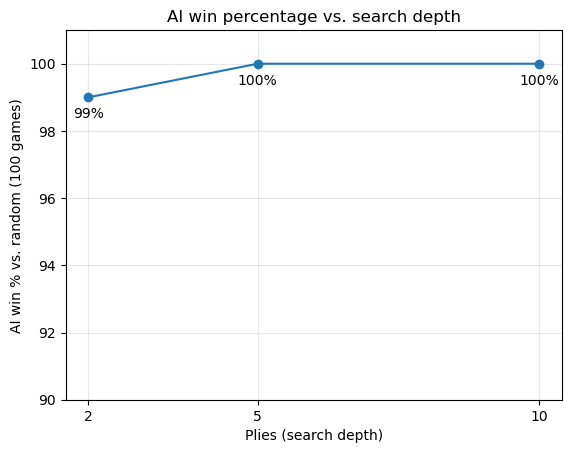

In [25]:
# -------------------- Win % vs Search Depth ------------------------------
plies = [2, 5, 10]
win_pct = [win2, win5, win10]

plt.plot(plies, win_pct, marker='o')
for x, y in zip(plies, win_pct):
    plt.annotate(f"{y:.0f}%", (x, y), textcoords="offset points", xytext=(0, -15), ha="center")

plt.xticks(plies)
plt.ylim(90, 101)
plt.xlabel("Plies (search depth)")
plt.ylabel("AI win % vs. random (100 games)")
plt.title("AI win percentage vs. search depth")
plt.grid(alpha=0.3)
plt.show()

In [26]:
# Part 3: rule tests. Run this cell without changing it.
def run_test(name, board, player, pits, expected_board, expected_player, expected_over):
    game = Mancala()
    game.board = list(board)
    game.current_player = player
    for pit in pits:
        game.play(pit)
    over = game.winning_eval()
    ok = game.board == expected_board and over == expected_over and (expected_over or game.current_player == expected_player)
    print(('PASS  ' if ok else 'FAIL  ') + name)
    if not ok:
        print(f'      start {list(board)}, Player {player} plays pit(s) {pits}')
        print(f'      expected {expected_board}' + ('' if expected_over else f', then Player {expected_player} to move') + (', game over' if expected_over else ''))
        print(f'      got      {game.board}, Player {game.current_player} to move, game over = {over}')
    return ok

# board layout: [P1 pits 1-6, P1 mancala, P2 pits 1-6, P2 mancala]
tests = [
    ("Extra turn: P1 opens with pit 3, last stone lands in P1's mancala",
     [4, 4, 4, 4, 4, 4, 0, 4, 4, 4, 4, 4, 4, 0], 1, [3],
     [4, 4, 0, 5, 5, 5, 1, 4, 4, 4, 4, 4, 4, 0], 1, False),
    ("No extra turn: P1 opens with pit 4, last stone lands on P2's side",
     [4, 4, 4, 4, 4, 4, 0, 4, 4, 4, 4, 4, 4, 0], 1, [4],
     [4, 4, 4, 0, 5, 5, 1, 5, 4, 4, 4, 4, 4, 0], 2, False),
    ('Extra turn for Player 2',
     [4, 4, 4, 0, 5, 5, 1, 5, 4, 4, 4, 4, 4, 0], 2, [3],
     [4, 4, 4, 0, 5, 5, 1, 5, 4, 0, 5, 5, 5, 1], 2, False),
    ("Full lap: skip P2's mancala and finish in P1's mancala",
     [1, 1, 1, 1, 1, 14, 0, 1, 1, 1, 1, 1, 1, 0], 1, [6],
     [2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 0], 1, False),
    ('Two extra turns in a row (pit 6, then pit 5)',
     [3, 0, 0, 0, 2, 1, 0, 4, 4, 4, 4, 4, 4, 0], 1, [6, 5],
     [3, 0, 0, 0, 0, 1, 2, 4, 4, 4, 4, 4, 4, 0], 1, False),
    ('Capture: last stone in an empty P1 pit takes the opposite pit',
     [0, 1, 0, 0, 0, 3, 0, 4, 4, 4, 4, 4, 4, 0], 1, [2],
     [0, 0, 0, 0, 0, 3, 5, 4, 4, 4, 0, 4, 4, 0], 2, False),
    ('Capture when the opposite pit is empty: only the landing stone',
     [0, 1, 0, 0, 0, 3, 0, 4, 4, 4, 0, 4, 4, 0], 1, [2],
     [0, 0, 0, 0, 0, 3, 1, 4, 4, 4, 0, 4, 4, 0], 2, False),
    ("Last stone in own mancala empties P1's side: game ends, no extra turn",
     [0, 0, 0, 0, 0, 1, 10, 2, 2, 2, 2, 2, 2, 5], 1, [6],
     [0, 0, 0, 0, 0, 0, 11, 0, 0, 0, 0, 0, 0, 17], 1, True),
]

passed = sum(run_test(*t) for t in tests)
print(f'\n{passed} of {len(tests)} tests passed ({2.5 * passed} of 20 points)')


PASS  Extra turn: P1 opens with pit 3, last stone lands in P1's mancala
PASS  No extra turn: P1 opens with pit 4, last stone lands on P2's side
PASS  Extra turn for Player 2
PASS  Full lap: skip P2's mancala and finish in P1's mancala
PASS  Two extra turns in a row (pit 6, then pit 5)
PASS  Capture: last stone in an empty P1 pit takes the opposite pit
PASS  Capture when the opposite pit is empty: only the landing stone
Player 2 wins!
PASS  Last stone in own mancala empties P1's side: game ends, no extra turn

8 of 8 tests passed (20.0 of 20 points)


In [27]:
# ---------------- Item 9: AI test positions ----------------
positions = {
    "A": ([7, 7, 1, 0, 2, 0, 5, 0, 9, 9, 1, 1, 2, 4], 1),    # (board, depth d)
    "B": ([4, 10, 1, 4, 0, 1, 4, 1, 4, 4, 4, 4, 0, 7], 2),
    "C": ([3, 1, 1, 0, 2, 1, 10, 8, 2, 7, 0, 0, 0, 13], 2),
}

for name, (board, d) in positions.items():
    game = Mancala()
    game.board = list(board)
    game.current_player = 1
    with contextlib.redirect_stdout(io.StringIO()):
        mm = minimax_player(game, game, d)
        ab = alpha_beta_player(game, game, d)
    print(f"Position {name} (d={d}): minimax picks pit {mm}, Alpha-Beta picks pit {ab}")

Position A (d=1): minimax picks pit 5, Alpha-Beta picks pit 5
Position B (d=2): minimax picks pit 6, Alpha-Beta picks pit 6
Position C (d=2): minimax picks pit 6, Alpha-Beta picks pit 6
